In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import shap
import joblib
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv("../data/processed/train_engineered.csv")

xgb = joblib.load("../saved_models/xgboost.pkl")

imputer = joblib.load("../saved_models/imputer.pkl")

In [3]:
y = train["isFraud"]

X = train.drop(columns=["isFraud"])

In [4]:
from sklearn.preprocessing import LabelEncoder

cat_cols = X.select_dtypes(include=["object"]).columns

for col in cat_cols:
    X[col] = X[col].astype(str)
    X[col] = LabelEncoder().fit_transform(X[col])

In [5]:
X = pd.DataFrame(
    imputer.transform(X),
    columns=X.columns
)

In [6]:
explainer = shap.TreeExplainer(xgb)

In [7]:
sample = X.sample(1000, random_state=42)

shap_values = explainer.shap_values(sample)

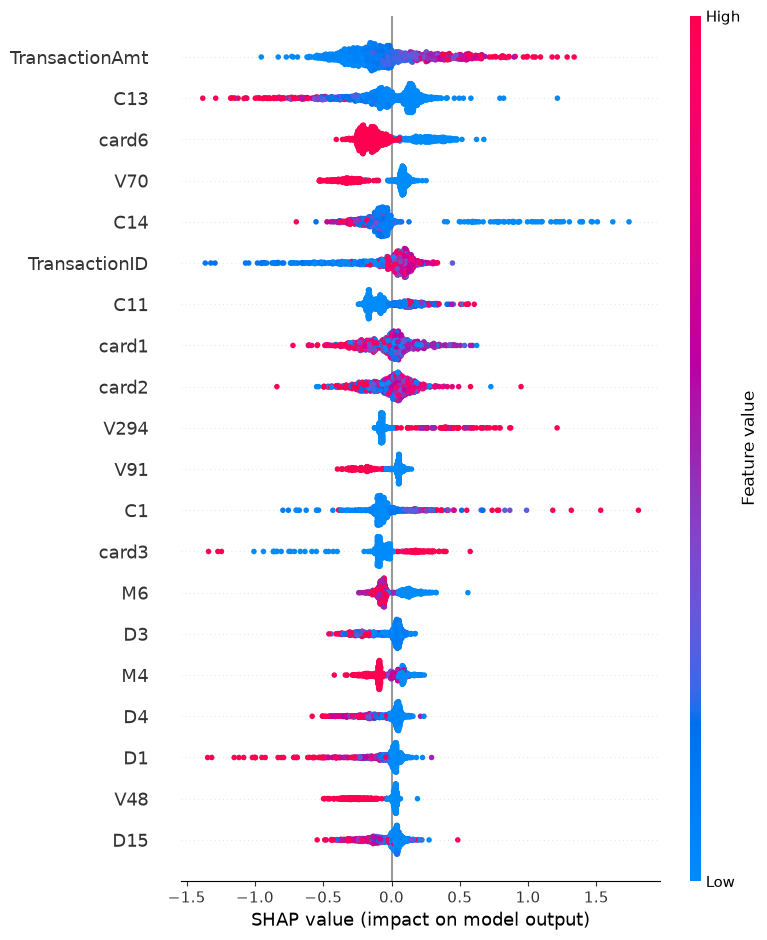

In [8]:
shap.summary_plot(
    shap_values,
    sample,
    show=False
)

plt.show()

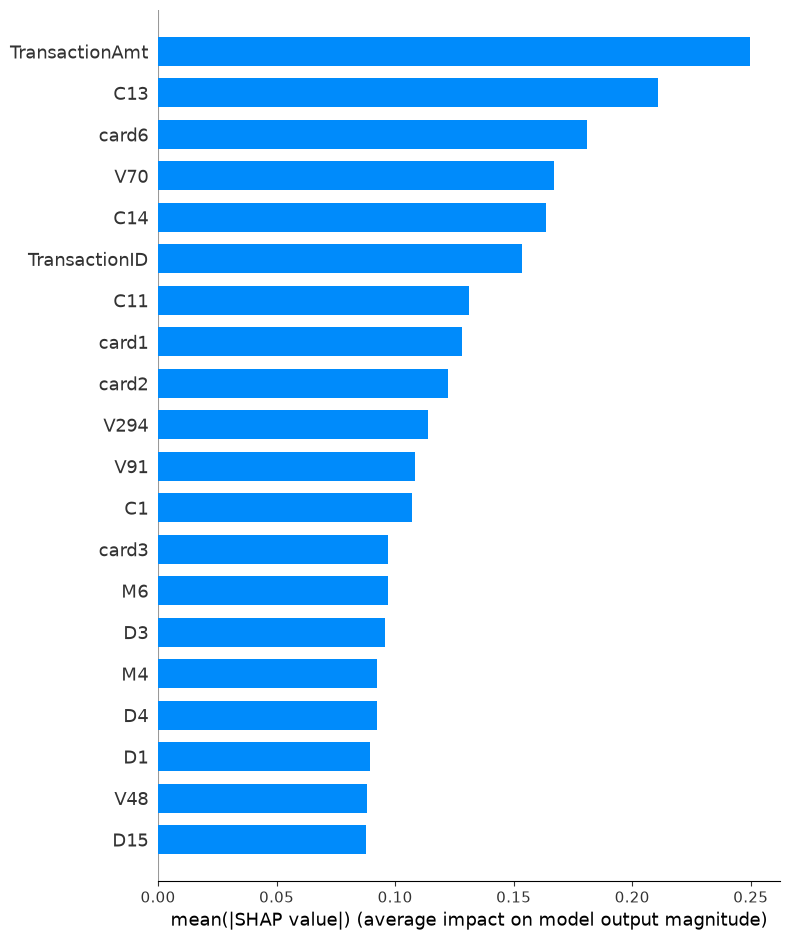

In [9]:
shap.summary_plot(
    shap_values,
    sample,
    plot_type="bar",
    show=False
)

plt.show()

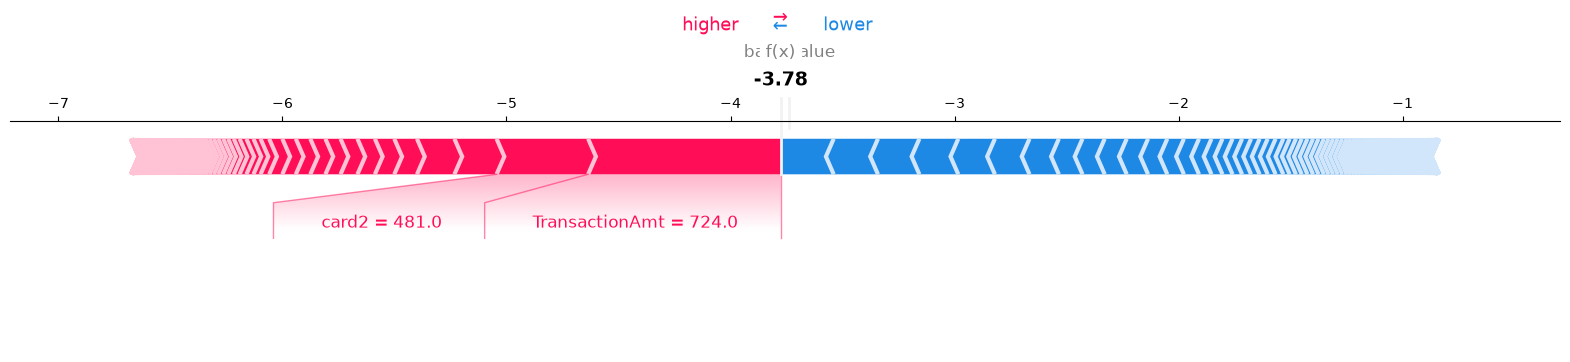

In [10]:
transaction = sample.iloc[[0]]

shap.force_plot(
    explainer.expected_value,
    explainer.shap_values(transaction),
    transaction,
    matplotlib=True
)

# Explainability Summary

SHAP (SHapley Additive exPlanations) was used to explain model predictions.

Benefits:

- Explains why a transaction is predicted as fraudulent
- Improves transparency
- Builds trust for financial institutions
- Helps investigators understand important risk factors